In [51]:
%pip install matplotlib
%pip install numpy
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [52]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

***NumPy*** ia a powerful Python library. It stands for Numerical Python. It provides support for multidimentional arrays, along with collection of matematical functions to operate on these arrays efficantly. NumPy is widely used in scientific computation, engineering and data science and analysis due to its speed and versatility. 

The ***scipy*** package contains various toolboxes dedicated to common issues in scientific computing. Its different submodules correspond to different applications, such as interpolation, integarion, optimization, image processing, statistics, special functions, etc.

In [53]:
auc_reference = np.array([145.2, 150.1, 138.4, 162.0, 140.5, 155.8, 149.0, 136.2, 158.4, 142.1, 148.0, 152.3])
auc_generic = np.array([142.8, 148.5, 135.0, 159.2, 138.1, 153.0, 146.5, 134.8, 155.0, 139.9, 145.2, 149.8])

Definition of the data: 

I created two arrays using np.array(). Each element in the array represents the measured area under the curve (AUC) for a specific patient (12 subjects in total). Each patient received both the original drug (auc_reference) and the generic drug (auc_generic).

***Area Under the Curve(AUC)*** 

 The tapezoidal rule is a numerical method frequently used in pharmacokinetics to calculate the area under the plasma drug concentration-versus-time curve, callled the area under the curve.



***Formula of AUC***:

By using:

Jupyter Notebook:

***The formula of the trapezoidal rule*** -  $\text{AUC}_n = \frac{C_{n-1} + C_n}{2} \times (t_n - t_{n-1})$, where  $({AUC}_n)$ - Area Under the Curve,

$(t_n)$, - time of observation of drug concentration $(C_{n})$ , and $(t_{n-1})$ - time of prior obsevation of drug concentartion corresponding to $(C_{n-1})$ 






$\textcolor{purple}{\textbf{Why Original / Generic Medication and AUC  are used in bioequivalence?}}$

What is a Original Medication?

Definition: This is the first drug developed and brought to market by the pharmaceutical company that invented it.

Key Features: To gain regulatory approval, it undergoes years of clinical trials to demonstrate safety and efficacy. It is protected by patents for a specific period.

What is a Generic Medication?
Definition: This is a medication developed after the patent for the original drug expires.

Key Features: It contains the exact same active pharmaceutical ingredient (API) in the same dose and dosage form (e.g., tablets) as the original. Its purpose is to deliver identical therapeutic efficacy at a significantly lower cost.


What is the Area Under the Curve (AUC)
?Definition: $\text{AUC}$ measures the total amount of active drug that reaches the systemic blood circulation over a specific timeframe (from time $t=0$ to time $t$).Significance: It directly reflects the total extent of drug absorption (systemic exposure) in the body.


$\text{AUC}_{\text{reference}}$ (Original): Serves as the benchmark or gold standard value.$\text{AUC}_{\text{generic}}$ (Generic): Represents the total absorption of the generic drug in the same subject.

Study Objective: To prove that the generic product is equally effective and safe, its $\text{AUC}_{\text{generic}}$ must be virtually identical to $\text{AUC}_{\text{reference}}$.

Mathematical Context: We evaluate the ratio of their geometric means ($\text{GMR} = \frac{\text{AUC}_{\text{generic}}}{\text{AUC}_{\text{reference}}}$). For bioequivalence to be declared, the 90% Confidence Interval for this ratio must fall entirely within the regulatory window of [80.00% – 125.00%].






![Figure 2.3: Trapezoidal rule formula for AUC calculation (Source: Applied Biopharmaceutics & Pharmacokinetics, Seventh Edition, Page 29).](29%20page.png)





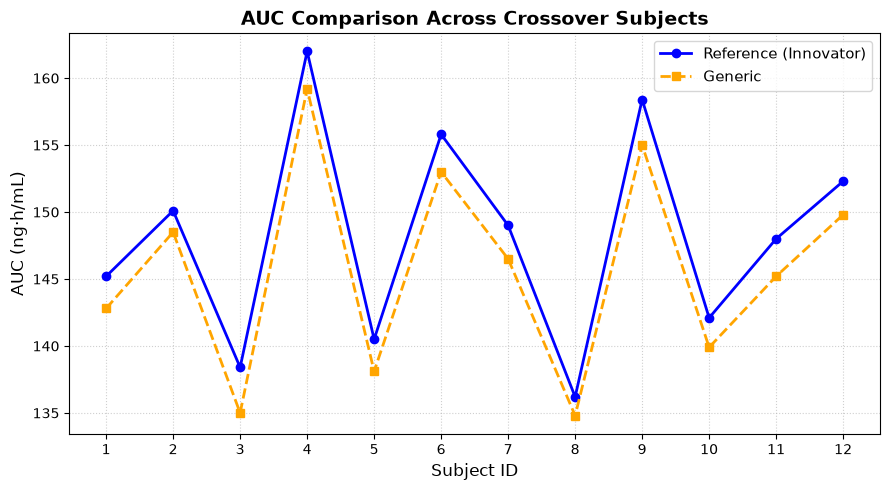

In [54]:
subjects = np.arange(1, len(auc_reference) + 1)

plt.figure(figsize=(9, 5))
plt.plot(subjects, auc_reference, marker='o', color='blue', linewidth=2, label='Reference (Innovator)')
plt.plot(subjects, auc_generic, marker='s', color='orange', linewidth=2, linestyle='--', label='Generic')

plt.title("AUC Comparison Across Crossover Subjects", fontsize=14, fontweight='bold')
plt.xlabel("Subject ID", fontsize=12)
plt.ylabel("AUC (ng·h/mL)", fontsize=12)
plt.xticks(subjects)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

***Plot 1: Subject-by-Subject AUC Comparison (Scatter / Line Plot)***
This plot visualizes how the generic and reference AUC values compare across all 12 individual crossover subjects.

In [55]:
def single_trapezoid_auc(t_prev, t_curr, c_prev, c_curr):
    avg_concentration = (c_prev + c_curr) / 2.0
    time_delta = t_curr - t_prev
    
    area = avg_concentration * time_delta
    return area

The Line 11 represents the function, created to show how to calculate AUC in Python.
Threa are the same parameters : time and concentration, represented on the picture above.

In [56]:
log_ref = np.log(auc_reference)
log_gen = np.log(auc_generic)

Calculation  of the natural logarithm of each AUC value

The Natural logarithm has the symbol "ln", which is the logarithm to base(the value of e is approximatlely 2.71828)

***Natural logarithm***, related to pharmacocinetics(AUC of Generic and Reference):
\begin{align*}
\text{log\_ref} &= \ln(\text{AUC}_{\text{reference}}) \\
\text{log\_gen} &= \ln(\text{AUC}_{\text{generic}})
\end{align*}





In [57]:
log_diff = log_gen - log_ref


$\textcolor{purple}{\textbf{Why it is used in bioequivalence?}}$

To calculate the difference 

\begin{align*}
\ln(\text{AUC}_{\text{ref}}) &= \ln(\text{AUC}_{\text{reference}}) \\
\ln(\text{AUC}_{\text{gen}}) &= \ln(\text{AUC}_{\text{generic}}) \\[8pt]
\Delta \ln(\text{AUC}) &= \ln(\text{AUC}_{\text{gen}}) - \ln(\text{AUC}_{\text{ref}}) = \ln\left(\frac{\text{AUC}_{\text{generic}}}{\text{AUC}_{\text{reference}}}\right)
\end{align*}

We extract the logarithmic values for each patient. This gives us the logarithmic ratio of the generic drug to the originator for each of the 12 individuals.




In [58]:
mean_diff = np.mean(log_diff)
sem_diff = stats.sem(log_diff)

The ***Mean*** and The ***Standard Error of the Mean***(SEM)

mean_diff = np.mean(...): Uses NumPy to calculate the arithmetic mean of the logarithmic differences.

Definition of the mean: The arithmetic average of a set of numbers.
Usage: To find the average of the set of data.

$\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i$  

  Sample Mean Formula

$\mu = \frac{1}{N} \sum_{i=1}^{N} x_i$    

  Population Mean Formula 


sem_diff = stats.sem(...): Uses SciPy (scipy.stats). Calculates the Standard Error of the Mean (SEM). 
Usage: It indicates how much our sample varies relative to the entire population.

$\sigma_{\bar{x}} = \frac{\sigma}{\sqrt{n}}$







$\textcolor{purple}{\textbf{Why the  Mean and the Standard Error of the Mean(SEM)
 are used in bioequivalence?}}$

  The Role of the Mean ($\text{Mean}$ / $\bar{x}$)

Central Point Estimate: Calculates the average exposure ($\text{AUC}$) across all test subjects in log-scale:$$\Delta \bar{x} = \text{Mean}(\ln(\text{Generic})) - \text{Mean}(\ln(\text{Reference})) = \ln\left(\frac{\text{Geometric Mean}_{\text{Generic}}}{\text{Geometric Mean}_{\text{Reference}}}\right)$$

Center of the Interval: Exponentiating this value ($\exp(\Delta \bar{x}) \times 100$) yields the Geometric Mean Ratio (GMR), which serves as the midpoint of the 90% Confidence Interval.

  The Role of the Standard Error of the Mean ($\text{SEM}$)
 
 Quantifying Precision: Measures the variability and uncertainty of the sample mean relative to the true population mean:$$\text{SEM} = \frac{s}{\sqrt{n}}$$(where $s$ is the sample standard deviation of differences and $n$ is the number of subjects).
 
 Margin of Error Calculation: Directly dictates the width of the confidence interval boundary:$$\text{Margin of Error} = t_{\text{crit}} \times \text{SEM}$$
 
 Sample Size Effect: As the sample size ($n$) increases, $\text{SEM}$ decreases, producing a narrower confidence interval and higher statistical precision.
 
 Combined Application in the 90% Confidence IntervalIn bioequivalence evaluation (under the Two One-Sided Tests / TOST framework), the Mean provides the location, while the $\text{SEM}$ (combined with $t_{\text{crit}}$) sets the width:$$\text{Confidence Interval}_{\text{log}} = \text{Mean Difference} \pm \left(t_{\text{crit}} \times \text{SEM}\right)$$
 
 
 Converting these limits back to the linear scale via exponentiation ensures that the entire 90% Confidence Interval can be objectively tested against the regulatory range of [80.00% – 125.00%].

In [59]:
n = len(auc_reference)
df = n - 1

The degree of fredom shows how many  elements there are in one sample minus 1.

The range of freedom, depending on the hypotesis testing.







$\textcolor{purple}{\textbf{Why it is used in bioequivalence?}}$


The degree of freedom is used in bioequivalence to count the possible opportunities to confirm the bioequivalence of the two drugs.

In [60]:
t_crit = stats.t.ppf(0.95, df=df)

***Definition of Critical t-Value***

The critical ***t-value ($t_{\text{crit}}$)*** is a threshold value derived from Student's t-distribution that defines the boundary between the acceptance region and the rejection region in statistical hypothesis testing. It indicates the number of standard errors required to move away from the mean to cover a specified level of statistical confidence (e.g., 90%).

Key Parameters Required to Determine ***Significance Level ($\alpha$)***: The probability of committing a Type I error (false positive). For a 90% confidence interval, the significance level is $\alpha = 0.10$.
Type of Test: Under the Two One-Sided Tests (TOST) framework used in bioequivalence, the significance level is divided between both tails ($\alpha / 2 = 0.05$), focusing on the upper 95th percentile quantile ($q = 0.95$).
***Degrees of Freedom ($df$)***: A parameter depending on the sample size ($df = n - 1$) that dictates the exact shape and tail thickness of Student's t-distribution.

In pharmacokinetic analysis, $t_{\text{crit}}$ is directly applied to calculate the Margin of Error when constructing the 90% Confidence Interval for logarithmic differences: $$\text{Margin of Error} = t_{\text{crit}} \times \text{SEM}$$
$$\text{Confidence Interval}_{\text{log}} = \text{Mean Difference} \pm (t_{\text{crit}} \times \text{SEM})$$

Mathematical Formula for $t_{\text{crit}}$ (Quantile Function)The critical t-value is mathematically computed using the Inverse Cumulative Distribution Function (Quantile Function / Percent Point Function):$$t_{\text{crit}} = t_{1 - \alpha/2, \, df} = F^{-1}\left(1 - \frac{\alpha}{2}, \, df\right)$$
For a 90% Confidence Interval ($\alpha = 0.10 \Rightarrow 1 - \alpha/2 = 0.95$) with sample size $n$:

\begin{align*}
t_{\text{crit}} &= F^{-1}(0.95, \, df) \\[6pt]
\text{where:} \quad df &= n - 1
\end{align*}

Python Implementation: In SciPy, this mathematical inverse function corresponds directly to:

Pythont_crit = stats.t.ppf(0.95, df=df)


Syntax:

***scipy.stats.t.ppf(q, df)***

Parameters:

***q: The critical level to use.
df: The degrees of freedom.***


Image: ...... 







***Critical T-Value Analysis***

For calculating the t - critical value is used  $t{_\text{crit}}$ in  **90% confidence interval** we use the fuction `stats.t.ppf()` from the library **SciPy**.

> **Formula:** `t_crit = stats.t.ppf(0.95, df=df)`

***Critical T- Value***

Formula :   $\quad t_{\alpha/2, n-1} \quad \text{or} \quad t_{\frac{\alpha}{2}, \nu}$

***Usage of Critical T - Value*** of proving the Bioequivalence

$\textcolor{purple}{\textbf{Why it is used in bioequivalence?}}$

1. Normal and Log-Normal Distribution 
Biological Variability: Drug absorption and elimination naturally vary from person to person. To make valid statistical inferences about the whole population using a small sample of subjects (e.g., 12 or 24 subjects), a mathematical distribution model is required.
Log-Transformation ($\ln$): Pharmacokinetic parameters like $\text{AUC}$ and $C_{\max}$ follow a log-normal distribution (their raw data is skewed). Applying a natural logarithm ($\ln$) converts the data into a normal distribution, allowing the use of standard parametric statistics (such as t-tests).



2. Student’s t-Distribution & Critical t-Value ($t_{\text{crit}}$)
Small Sample Sizes ($n$): Bioequivalence clinical trials are conducted on a limited number of healthy volunteers. The standard Normal ($Z$) distribution requires a large sample size or known population variance ($\sigma$). When the true population variance is unknown and estimated from the sample standard deviation ($s$), Student's t-distribution must be used.Accounting for Uncertainty: Student’s t-distribution has "heavier tails" than the standard normal distribution, which accounts for the extra uncertainty coming from small sample sizes and yields reliable confidence intervals.



3. Degrees of Freedom ($df$)
Defining Curve Shape: The shape of Student's t-distribution depends directly on the degrees of freedom. For paired crossover study designs with $n$ subjects:

    df = n - 1  
    Determining  $t_{\text{crit}}:$

    The degrees of freedom dictate the exact critical value $t_{\text{crit}}$ obtained from scipy.stats.t.ppf() to calculate the Margin of Error.
 
4. Application in the TOST Framework
Under regulatory frameworks (EMA/FDA), bioequivalence uses Two One-Sided Tests (TOST) to construct a 90% Confidence Interval on the log scale:
 
$\text{Margin of Error}$ = $t_{\text{crit}} \times \text{SEM}$ 

$\text{CI}_{\text{log}} = \bar{d} \pm (t_{\text{crit}} \times \text{SEM})$
 
Exponentiating ($\exp$) these logarithmic boundaries converts them back to the linear percentage scale to confirm whether the entire interval falls strictly within the regulatory acceptance range of [80.00% – 125.00%].





In [61]:
ci_lower_log = mean_diff - (t_crit * sem_diff)
ci_upper_log = mean_diff + (t_crit * sem_diff)

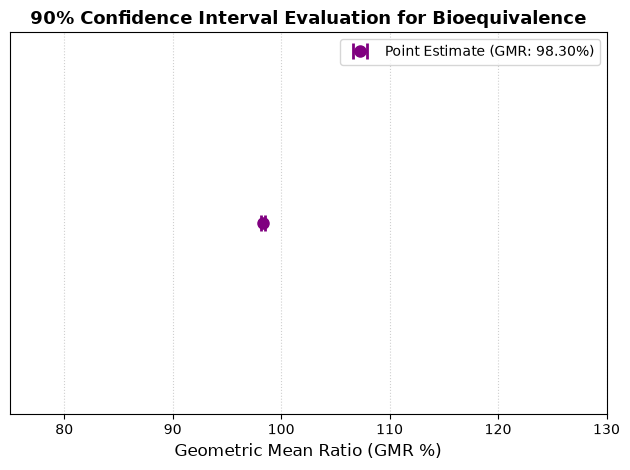

In [62]:
plt.errorbar(
    x=point_estimate, y=1,
    xerr=[[point_estimate - ci_lower], [ci_upper - point_estimate]],
    fmt='o', color='purple', ecolor='purple', elinewidth=2.5, capsize=6, capthick=2,
    markersize=8, label=f'Point Estimate (GMR: {point_estimate:.2f}%)'
)

plt.title("90% Confidence Interval Evaluation for Bioequivalence", fontsize=13, fontweight='bold')
plt.xlabel("Geometric Mean Ratio (GMR %)", fontsize=12)
plt.yticks([])  # Hide Y-axis ticks
plt.xlim(75, 130)
plt.legend(loc='upper right', fontsize=10)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

***Plot 2: 90% Confidence Interval vs. Regulatory Acceptance Range***
This plot visualizes whether the calculated 90% Confidence Interval for the Geometric Mean Ratio (GMR) falls completely within the 80.00% – 125.00% acceptance window.

Formula, describing the ***Confidence Interval with its boundaries - upper and lower***


To write the upper and lower boundaries of a confidence interval
$$
\begin{aligned}
\text{Lower Bound} &= \bar{x} - z^* \left(\frac{s}{\sqrt{n}}\right) \\
\text{Upper Bound} &= \bar{x} + z^* \left(\frac{s}{\sqrt{n}}\right)
\end{aligned}
$$


$\textcolor{purple}{\textbf{Why it is used in bioequivalence?}}$


By calculating  the  upper and the  lower boundaries of Confidence Interval, we can estimate if the two medications are with the same bioequivalnce.

In [63]:
ci_lower = np.exp(ci_lower_log) * 100
ci_upper = np.exp(ci_upper_log) * 100
point_estimate = np.exp(mean_diff) * 100

****Confidence Interval with its boundaries - upper and lower****

$$
\begin{aligned}
\text{Lower Bound} &= \bar{x} - z^* \left(\frac{s}{\sqrt{n}}\right) \\
\text{Upper Bound} &= \bar{x} + z^* \left(\frac{s}{\sqrt{n}}\right)
\end{aligned}
$$



$\textcolor{purple}{\textbf{Why it is used in bioequivalence?}}$

By calculating  the  upper and the  lower boundaries of Confidence Interval, we can estimate if the two medications are with the same bioequivalnce.

***Plot 3: Distribution of Log-Differences***

This plot visualizes the individual log-scale AUC differences ($\Delta \ln(\text{AUC})$) to check sample distribution and central tendency.

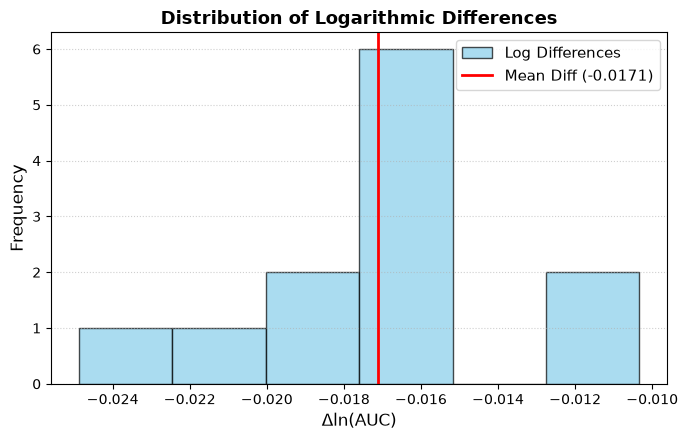

In [64]:
plt.figure(figsize=(7, 4.5))

plt.hist(log_diff, bins=6, color='skyblue', edgecolor='black', alpha=0.7, label='Log Differences')
plt.axvline(mean_diff, color='red', linestyle='-', linewidth=2, label=f'Mean Diff ({mean_diff:.4f})')

plt.title("Distribution of Logarithmic Differences", fontsize=13, fontweight='bold')
plt.xlabel(r'$\Delta \ln(\mathrm{AUC})$', fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [65]:
print("=== STATISTICAL ANALYSIS RESULTS ===")
print(f"Point Estimate (GMR): {point_estimate:.2f}%")
print(f"90% Confidence Interval: [{ci_lower:.2f}%, {ci_upper:.2f}%]\n")

if ci_lower >= 80.00 and ci_upper <= 125.00:
    print("CONCLUSION: The products are BIOEQUIVALENT.")
    print("Reason: The 90% Confidence Interval lies entirely within [80.00% - 125.00%].")
else:
    print("CONCLUSION: The products are NOT bioequivalent.")
    print("Reason: The confidence interval extends outside the regulatory boundaries.")

=== STATISTICAL ANALYSIS RESULTS ===
Point Estimate (GMR): 98.30%
90% Confidence Interval: [98.10%, 98.51%]

CONCLUSION: The products are BIOEQUIVALENT.
Reason: The 90% Confidence Interval lies entirely within [80.00% - 125.00%].


***$\textcolor{purple}{\textbf{Primary Academic Literature and Textbooks}}$***



***Applied Biopharmaceutics Pharmacokinetics (7th Ed.) By Leon Shargel and Andrew B.C. Yu***


***Regulatory Guidelines & Official Standards***

European Medicines Agency (EMA): Guideline on the Investigation of Bioequivalence (CPMP/EWP/QWP/1401/98 Rev. 1/ Corr ).

U.S. Food and Drug Administration (FDA): Bioavailability and Bioequivalence Studies Submitted in NDAs or INDs — General Considerations.

***Python Documentation & Scientific Libraries***

NumPy Developers: NumPy Reference Guide & Mathematical Functions. Available at: https://numpy.org/doc/

SciPy Community: SciPy Statistical Functions (scipy.stats). Available at: https://docs.scipy.org/doc/scipy/reference/stats.html

***Educational Online Resources & Lectures***

Interactive Jupyter Notebook Documentation: Markdown and LaTeX formatting guides for scientific computing.